In [ ]:
!pip -q install nltk gradio

In [ ]:
import pandas as pd
import numpy as np
import random
import re
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

random.seed(42)
np.random.seed(42)

print("Environment is ready!")

Environment is ready!


In [ ]:
# STEP 3: CREATE 100 SYNTHETIC USER PROFILES

mbti_types = [
    "INTJ", "INTP", "ENTJ", "ENTP",
    "INFJ", "INFP", "ENFJ", "ENFP",
    "ISTJ", "ISFJ", "ESTJ", "ESFJ",
    "ISTP", "ISFP", "ESTP", "ESFP"
]

locations = [
    "Bengaluru", "Mumbai", "Hyderabad", "Chennai",
    "Pune", "Delhi", "Kolkata", "Ahmedabad",
    "Jaipur", "Kochi"
]

# Each profession has a relevant industry and skill set.
career_options = [
    {
        "profession": "Data Analyst",
        "industry": "business analytics",
        "skills": ["SQL, Python and dashboard design",
                   "statistical analysis and data visualization",
                   "reporting, Excel and exploratory data analysis"],
        "goals": ["improve business decisions through data",
                  "develop advanced analytics solutions",
                  "specialize in predictive business intelligence"],
        "interests": ["Data Analysis", "Python", "Visualization"]
    },
    {
        "profession": "Software Developer",
        "industry": "software engineering",
        "skills": ["Python, APIs and database development",
                   "Java, testing and software design",
                   "web applications and backend engineering"],
        "goals": ["build reliable software products",
                  "design scalable digital applications",
                  "advance into software architecture"],
        "interests": ["Programming", "Software", "Technology"]
    },
    {
        "profession": "Machine Learning Engineer",
        "industry": "artificial intelligence",
        "skills": ["Python, model evaluation and feature engineering",
                   "deep learning, data pipelines and experimentation",
                   "scikit-learn, model deployment and statistics"],
        "goals": ["develop practical AI applications",
                  "build dependable predictive systems",
                  "specialize in intelligent recommendation systems"],
        "interests": ["AI", "Machine Learning", "Python"]
    },
    {
        "profession": "UX Designer",
        "industry": "product design",
        "skills": ["user research, wireframing and prototyping",
                   "interaction design and usability testing",
                   "design systems and accessibility"],
        "goals": ["create accessible digital experiences",
                  "lead user-centered product design",
                  "improve products through user research"],
        "interests": ["Design", "Creativity", "User Research"]
    },
    {
        "profession": "Business Analyst",
        "industry": "business consulting",
        "skills": ["requirements analysis and process mapping",
                   "stakeholder communication and reporting",
                   "business metrics and problem solving"],
        "goals": ["help organizations make informed decisions",
                  "lead process improvement initiatives",
                  "grow into strategic consulting"],
        "interests": ["Business", "Strategy", "Communication"]
    },
    {
        "profession": "Cybersecurity Analyst",
        "industry": "information security",
        "skills": ["network monitoring and threat analysis",
                   "security testing and incident response",
                   "risk assessment and secure systems"],
        "goals": ["protect organizations from cyber threats",
                  "specialize in security engineering",
                  "improve organizational security practices"],
        "interests": ["Cybersecurity", "Networks", "Technology"]
    },
    {
        "profession": "Digital Marketing Specialist",
        "industry": "digital marketing",
        "skills": ["SEO, campaign analytics and content planning",
                   "social media strategy and audience research",
                   "branding, advertising and performance reporting"],
        "goals": ["build effective digital campaigns",
                  "lead data-informed marketing strategy",
                  "grow into brand management"],
        "interests": ["Marketing", "Writing", "Creativity"]
    },
    {
        "profession": "Environmental Scientist",
        "industry": "environmental sustainability",
        "skills": ["environmental data analysis and field research",
                   "GIS, reporting and sustainability assessment",
                   "climate research and resource management"],
        "goals": ["support evidence-based environmental decisions",
                  "develop sustainable technology projects",
                  "contribute to climate resilience initiatives"],
        "interests": ["Environment", "Research", "Sustainability"]
    },
    {
        "profession": "Cloud Engineer",
        "industry": "cloud computing",
        "skills": ["cloud infrastructure and automation",
                   "Linux, networking and deployment pipelines",
                   "containerization and system monitoring"],
        "goals": ["build reliable cloud platforms",
                  "improve infrastructure scalability",
                  "specialize in cloud architecture"],
        "interests": ["Cloud", "Programming", "Infrastructure"]
    },
    {
        "profession": "HR Specialist",
        "industry": "human resources",
        "skills": ["recruitment, employee engagement and communication",
                   "workforce analytics and learning programs",
                   "talent development and organizational planning"],
        "goals": ["improve employee development",
                  "build inclusive workplace practices",
                  "grow into people management"],
        "interests": ["Mentoring", "Communication", "Leadership"]
    }
]

personality_options = [
    "I enjoy solving practical problems and learning new skills.",
    "I value thoughtful decisions, clear communication and steady progress.",
    "I like exchanging ideas and collaborating with people from different backgrounds.",
    "I am curious, adaptable and motivated by continuous improvement.",
    "I prefer organized work, realistic goals and dependable teamwork.",
    "I enjoy exploring creative ideas and turning them into useful outcomes.",
    "I value empathy, constructive feedback and supportive relationships.",
    "I like independent research as well as sharing knowledge with others."
]

work_styles = [
    "I work best when expectations are clear and progress can be measured.",
    "I enjoy collaborative projects where everyone contributes their strengths.",
    "I balance independent focus with regular discussions and feedback.",
    "I prefer an iterative approach, testing ideas and improving them over time.",
    "I appreciate flexible environments that encourage curiosity and initiative."
]

values = [
    "I value integrity, lifelong learning and meaningful work.",
    "I care about inclusion, responsibility and positive social impact.",
    "I value creativity, reliability and practical problem solving.",
    "I appreciate mentorship, mutual respect and shared success.",
    "I am motivated by innovation, growth and continuous improvement."
]

all_profiles = []

for i in range(1, 101):
    career = career_options[(i - 1) % len(career_options)]

    name = f"User{i:03d}"
    user_id = f"U{i:03d}"

    age = random.randint(20, 45)
    location = random.choice(locations)
    experience_years = random.randint(0, min(20, age - 18))

    skills = random.choice(career["skills"])
    goal = random.choice(career["goals"])

    professional_summary = (
        f"A professional in {career['industry']} with "
        f"{experience_years} years of experience. "
        f"Skilled in {skills}, with a goal to {goal}."
    )

    about_me = (
        f"{random.choice(personality_options)} "
        f"{random.choice(work_styles)} "
        f"{random.choice(values)}"
    )

    # Role-related MBTI assignments provide some realism.
    if career["profession"] in [
        "Data Analyst", "Machine Learning Engineer"
    ]:
        mbti = random.choice(["INTJ", "INTP", "ISTJ", "ENTP"])
    elif career["profession"] in [
        "Business Analyst", "HR Specialist"
    ]:
        mbti = random.choice(["ENTJ", "ENFJ", "ESTJ", "ESFJ"])
    elif career["profession"] == "UX Designer":
        mbti = random.choice(["INFP", "ENFP", "ISFP", "ESFP"])
    else:
        mbti = random.choice(mbti_types)

    interests = random.sample(
        career["interests"], k=min(3, len(career["interests"]))
    )

    # Add a few additional interests to diversify profiles.
    extra_interests = [
        "Reading", "Fitness", "Teaching", "Entrepreneurship",
        "Research", "Mentoring", "Teamwork", "Public Speaking",
        "Sustainability", "Leadership"
    ]

    for interest in random.sample(extra_interests, 2):
        if interest not in interests:
            interests.append(interest)

    all_profiles.append({
        "user_id": user_id,
        "name": name,
        "age": age,
        "location": location,
        "profession": career["profession"],
        "experience_years": experience_years,
        "professional_summary": professional_summary,
        "about_me": about_me,
        "mbti": mbti,
        "interests": ", ".join(interests)
    })

users_df = pd.DataFrame(all_profiles)

# Save the dataset to CSV.
users_df.to_csv("users.csv", index=False)

print("Dataset created successfully!")
print("Number of users:", len(users_df))
print("Number of columns:", len(users_df.columns))
print("\nColumn names:")
print(users_df.columns.tolist())

display(users_df.head(5))

Dataset created successfully!
Number of users: 100
Number of columns: 10

Column names:
['user_id', 'name', 'age', 'location', 'profession', 'experience_years', 'professional_summary', 'about_me', 'mbti', 'interests']


,user_id,name,age,location,profession,experience_years,professional_summary,about_me,mbti,interests
0,U001,User001,40,Mumbai,Data Analyst,0,A professional in business analytics with 0 ye...,"I am curious, adaptable and motivated by conti...",INTJ,"Visualization, Data Analysis, Python, Reading,..."
1,U002,User002,22,Chennai,Software Developer,1,A professional in software engineering with 1 ...,I enjoy solving practical problems and learnin...,ISFP,"Programming, Software, Technology, Reading, Te..."
2,U003,User003,42,Kolkata,Machine Learning Engineer,10,A professional in artificial intelligence with...,"I am curious, adaptable and motivated by conti...",INTJ,"Machine Learning, AI, Python, Mentoring, Research"
3,U004,User004,45,Bengaluru,UX Designer,14,A professional in product design with 14 years...,"I value empathy, constructive feedback and sup...",ISFP,"User Research, Creativity, Design, Fitness, Re..."
4,U005,User005,41,Chennai,Business Analyst,9,A professional in business consulting with 9 y...,"I value thoughtful decisions, clear communicat...",ESFJ,"Communication, Strategy, Business, Mentoring, ..."


In [ ]:
# STEP 4: DATA QUALITY CHECKS

allowed_mbti = set(mbti_types)

print("Total rows:", len(users_df))
print("Unique user IDs:", users_df["user_id"].nunique())
print("Duplicate rows:", users_df.duplicated().sum())

required_columns = [
    "user_id", "name", "age", "location", "profession",
    "experience_years", "professional_summary", "about_me",
    "mbti", "interests"
]

print("Missing columns:",
      set(required_columns) - set(users_df.columns))

text_columns = [
    "name", "location", "profession",
    "professional_summary", "about_me", "interests"
]

print("\nEmpty text fields:")
print(users_df[text_columns].apply(
    lambda col: col.astype(str).str.strip().eq("").sum()
))

print("\nInvalid MBTI values:",
      (~users_df["mbti"].isin(allowed_mbti)).sum())

print("\nInvalid ages:",
      ((users_df["age"] < 20) | (users_df["age"] > 45)).sum())

print("\nExperience greater than age minus 18:",
      (users_df["experience_years"] > users_df["age"] - 18).sum())

assert len(users_df) >= 50
assert users_df["user_id"].is_unique
assert users_df.duplicated().sum() == 0
assert users_df[text_columns].notna().all().all()
assert users_df[text_columns].apply(
    lambda col: col.astype(str).str.strip().ne("").all()
).all()
assert users_df["mbti"].isin(allowed_mbti).all()

print("\nAll required profile validation checks passed!")

Total rows: 100
Unique user IDs: 100
Duplicate rows: 0
Missing columns: set()

Empty text fields:
name                    0
location                0
profession              0
professional_summary    0
about_me                0
interests               0
dtype: int64

Invalid MBTI values: 0

Invalid ages: 0

Experience greater than age minus 18: 0

All required profile validation checks passed!


In [ ]:
# STEP 5: GENERATE SYNTHETIC ACCEPT/REJECT FEEDBACK

feedback_rng = random.Random(2026)
feedback_rows = []

# Store profile data for easy lookup.
profile_lookup = users_df.set_index("user_id").to_dict("index")

all_user_ids = users_df["user_id"].tolist()

for viewer_id in all_user_ids:
    possible_matches = [
        uid for uid in all_user_ids if uid != viewer_id
    ]

    # Every viewer receives 8 unique candidate interactions.
    selected_matches = feedback_rng.sample(possible_matches, 8)

    viewer = profile_lookup[viewer_id]
    viewer_interests = {
        item.strip().lower()
        for item in viewer["interests"].split(",")
    }

    for matched_id in selected_matches:
        candidate = profile_lookup[matched_id]

        candidate_interests = {
            item.strip().lower()
            for item in candidate["interests"].split(",")
        }

        union = viewer_interests | candidate_interests
        intersection = viewer_interests & candidate_interests

        interest_overlap = (
            len(intersection) / len(union) if union else 0
        )

        same_profession = (
            viewer["profession"] == candidate["profession"]
        )
        same_location = (
            viewer["location"] == candidate["location"]
        )

        # Synthetic preference score, not a real human judgment.
        preference_score = (
            0.55 * interest_overlap
            + 0.25 * int(same_profession)
            + 0.20 * int(same_location)
        )

        # Keep a baseline acceptance probability and add noise.
        acceptance_probability = min(
            0.90, max(0.10, 0.20 + preference_score)
        )

        action = int(
            feedback_rng.random() < acceptance_probability
        )

        timestamp = (
            datetime(2025, 1, 1)
            + timedelta(days=feedback_rng.randint(0, 364),
                        hours=feedback_rng.randint(0, 23),
                        minutes=feedback_rng.randint(0, 59))
        )

        feedback_rows.append({
            "user_id": viewer_id,
            "matched_user_id": matched_id,
            "action": action,
            "timestamp": timestamp.strftime("%Y-%m-%d %H:%M:%S")
        })

feedback_df = pd.DataFrame(feedback_rows)

# Save the feedback dataset.
feedback_df.to_csv("feedback.csv", index=False)

print("Feedback dataset created!")
print("Total interactions:", len(feedback_df))
print("Acceptances:", int(feedback_df["action"].sum()))
print("Rejections:", int((feedback_df["action"] == 0).sum()))
print("Acceptance rate:",
      round(feedback_df["action"].mean() * 100, 2), "%")

display(feedback_df.head(10))

Feedback dataset created!
Total interactions: 800
Acceptances: 260
Rejections: 540
Acceptance rate: 32.5 %


,user_id,matched_user_id,action,timestamp
0,U001,U017,0,2025-08-04 18:35:00
1,U001,U042,0,2025-09-09 18:28:00
2,U001,U066,1,2025-11-11 02:07:00
3,U001,U067,0,2025-02-20 14:00:00
4,U001,U084,0,2025-12-17 15:43:00
5,U001,U015,0,2025-07-23 08:22:00
6,U001,U030,0,2025-07-02 12:47:00
7,U001,U078,0,2025-02-09 23:21:00
8,U002,U013,0,2025-10-23 09:01:00
9,U002,U073,0,2025-07-08 11:29:00


In [ ]:
# STEP 6: FEEDBACK DATA QUALITY CHECKS

print("Feedback rows:", len(feedback_df))
print("Duplicate interaction pairs:",
      feedback_df.duplicated(
          subset=["user_id", "matched_user_id"]
      ).sum())

print("Missing values:")
print(feedback_df.isnull().sum())

print("Invalid actions:",
      (~feedback_df["action"].isin([0, 1])).sum())

print("Unknown viewer IDs:",
      (~feedback_df["user_id"].isin(users_df["user_id"])).sum())

print("Unknown matched IDs:",
      (~feedback_df["matched_user_id"].isin(users_df["user_id"])).sum())

print("Self-matches:",
      (feedback_df["user_id"] ==
       feedback_df["matched_user_id"]).sum())

interactions_per_user = feedback_df.groupby("user_id").size()

print("\nMinimum interactions per user:",
      interactions_per_user.min())
print("Maximum interactions per user:",
      interactions_per_user.max())

assert len(feedback_df) >= 100
assert feedback_df.isnull().sum().sum() == 0
assert feedback_df.duplicated(
    subset=["user_id", "matched_user_id"]
).sum() == 0
assert feedback_df["action"].isin([0, 1]).all()
assert feedback_df["user_id"].isin(users_df["user_id"]).all()
assert feedback_df["matched_user_id"].isin(users_df["user_id"]).all()
assert (feedback_df["user_id"] !=
        feedback_df["matched_user_id"]).all()
assert interactions_per_user.min() >= 5
assert interactions_per_user.max() <= 10

print("\nAll feedback validation checks passed!")

Feedback rows: 800
Duplicate interaction pairs: 0
Missing values:
user_id            0
matched_user_id    0
action             0
timestamp          0
dtype: int64
Invalid actions: 0
Unknown viewer IDs: 0
Unknown matched IDs: 0
Self-matches: 0

Minimum interactions per user: 8
Maximum interactions per user: 8

All feedback validation checks passed!


In [ ]:
from google.colab import files

files.download("users.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("feedback.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import numpy as np

users_df = pd.read_csv("users.csv")
feedback_df = pd.read_csv("feedback.csv")

print("Users dataset:", users_df.shape)
print("Feedback dataset:", feedback_df.shape)

display(users_df.head(3))
display(feedback_df.head(3))

Users dataset: (100, 10)
Feedback dataset: (800, 4)


,user_id,name,age,location,profession,experience_years,professional_summary,about_me,mbti,interests
0,U001,User001,40,Mumbai,Data Analyst,0,A professional in business analytics with 0 ye...,"I am curious, adaptable and motivated by conti...",INTJ,"Visualization, Data Analysis, Python, Reading,..."
1,U002,User002,22,Chennai,Software Developer,1,A professional in software engineering with 1 ...,I enjoy solving practical problems and learnin...,ISFP,"Programming, Software, Technology, Reading, Te..."
2,U003,User003,42,Kolkata,Machine Learning Engineer,10,A professional in artificial intelligence with...,"I am curious, adaptable and motivated by conti...",INTJ,"Machine Learning, AI, Python, Mentoring, Research"


,user_id,matched_user_id,action,timestamp
0,U001,U017,0,2025-08-04 18:35:00
1,U001,U042,0,2025-09-09 18:28:00
2,U001,U066,1,2025-11-11 02:07:00


In [ ]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_columns = [
    "professional_summary",
    "about_me",
    "interests"
]

# Handle missing values before combining the text.
for col in text_columns:
    users_df[col] = users_df[col].fillna("").astype(str)

users_df["combined_text"] = (
    users_df["professional_summary"] + " " +
    users_df["about_me"] + " " +
    users_df["interests"]
)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

users_df["cleaned_text"] = (
    users_df["combined_text"].apply(clean_text)
)

display(users_df[
    ["name", "professional_summary", "cleaned_text"]
].head(5))

,name,professional_summary,cleaned_text
0,User001,A professional in business analytics with 0 ye...,a professional in business analytics with year...
1,User002,A professional in software engineering with 1 ...,a professional in software engineering with ye...
2,User003,A professional in artificial intelligence with...,a professional in artificial intelligence with...
3,User004,A professional in product design with 14 years...,a professional in product design with years of...
4,User005,A professional in business consulting with 9 y...,a professional in business consulting with yea...


TF-IDF matrix shape: (100, 986)
Similarity matrix shape: (100, 100)


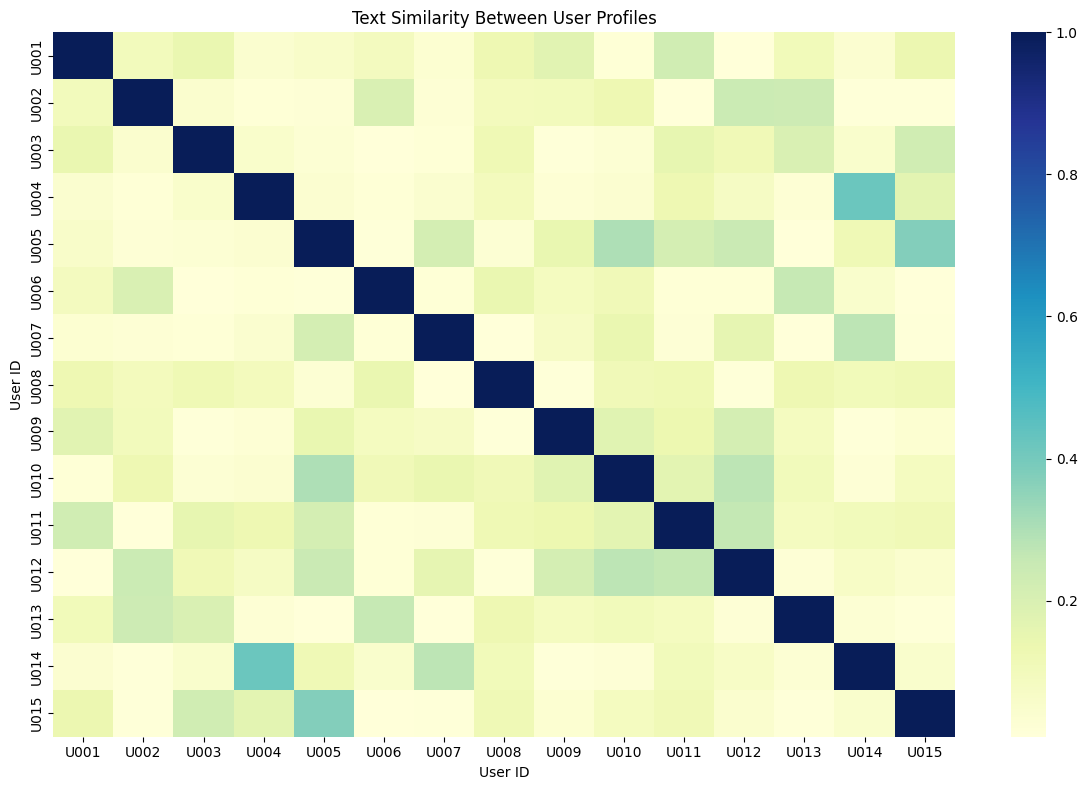

In [ ]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    max_features=5000
)

tfidf_matrix = vectorizer.fit_transform(
    users_df["cleaned_text"]
)

text_similarity = cosine_similarity(tfidf_matrix)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Similarity matrix shape:", text_similarity.shape)

# Visualize a sample of the first 15 profiles.
plt.figure(figsize=(12, 8))
sns.heatmap(
    text_similarity[:15, :15],
    cmap="YlGnBu",
    xticklabels=users_df["user_id"].iloc[:15],
    yticklabels=users_df["user_id"].iloc[:15]
)
plt.title("Text Similarity Between User Profiles")
plt.xlabel("User ID")
plt.ylabel("User ID")
plt.tight_layout()
plt.show()

In [ ]:
# Map every user ID to its position in the similarity matrix.
user_index = {
    user_id: i
    for i, user_id in enumerate(users_df["user_id"])
}

INITIAL_WEIGHTS = {
    "text": 0.50,
    "mbti": 0.30,
    "location": 0.20
}

def calculate_pair_features(user_id, matched_user_id):
    user_a = users_df.iloc[user_index[user_id]]
    user_b = users_df.iloc[user_index[matched_user_id]]

    # 1. NLP similarity score
    text_score = (
        text_similarity[
            user_index[user_id],
            user_index[matched_user_id]
        ] * 100
    )

    # 2. MBTI letter-position similarity heuristic
    mbti_a = user_a["mbti"]
    mbti_b = user_b["mbti"]

    mbti_score = (
        sum(a == b for a, b in zip(mbti_a, mbti_b)) / 4
    ) * 100

    # 3. Location score
    location_score = (
        100 if user_a["location"] == user_b["location"]
        else 40
    )

    return {
        "text": float(text_score),
        "mbti": float(mbti_score),
        "location": float(location_score)
    }

def calculate_compatibility(
    user_id, matched_user_id, weights=None
):
    if user_id == matched_user_id:
        raise ValueError("A user cannot be matched with themselves.")

    if user_id not in user_index or matched_user_id not in user_index:
        raise ValueError("Unknown user ID.")

    if weights is None:
        weights = INITIAL_WEIGHTS

    features = calculate_pair_features(
        user_id, matched_user_id
    )

    score = sum(
        weights[key] * features[key]
        for key in features
    )

    return round(float(np.clip(score, 0, 100)), 2)

# Test with two profiles.
user_a = users_df.iloc[0]["user_id"]
user_b = users_df.iloc[1]["user_id"]

print("User A:", user_a)
print("User B:", user_b)
print("Features:", calculate_pair_features(user_a, user_b))
print(
    "Compatibility:",
    calculate_compatibility(user_a, user_b),
    "%"
)

User A: U001
User B: U002
Features: {'text': 10.074553745803046, 'mbti': 25.0, 'location': 40.0}
Compatibility: 20.54 %


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Construct the feature table using recorded feedback pairs.
feature_rows = []

for _, row in feedback_df.iterrows():
    features = calculate_pair_features(
        row["user_id"],
        row["matched_user_id"]
    )

    feature_rows.append(features)

X = pd.DataFrame(feature_rows)[
    ["text", "mbti", "location"]
]

y = feedback_df["action"].astype(int)

print("Feature matrix:", X.shape)
print("Feedback labels:", y.value_counts().to_dict())

Feature matrix: (800, 3)
Feedback labels: {0: 540, 1: 260}


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

feedback_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

feedback_model.fit(X_train, y_train)

predictions = feedback_model.predict(X_test)

In [ ]:
print("Accuracy:", round(
    accuracy_score(y_test, predictions), 3
))

print("Precision:", round(
    precision_score(y_test, predictions, zero_division=0), 3
))

print("Recall:", round(
    recall_score(y_test, predictions, zero_division=0), 3
))

print("F1-score:", round(
    f1_score(y_test, predictions, zero_division=0), 3
))

print("\nClassification report:")
print(classification_report(
    y_test, predictions, zero_division=0
))

Accuracy: 0.669
Precision: 0.48
Recall: 0.231
F1-score: 0.312

Classification report:
              precision    recall  f1-score   support

           0       0.70      0.88      0.78       108
           1       0.48      0.23      0.31        52

    accuracy                           0.67       160
   macro avg       0.59      0.56      0.55       160
weighted avg       0.63      0.67      0.63       160



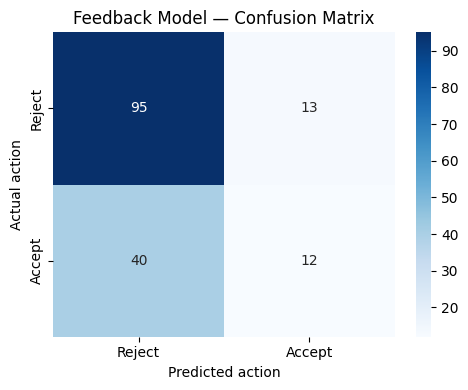

In [ ]:
cm = confusion_matrix(y_test, predictions, labels=[0, 1])

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Reject", "Accept"],
    yticklabels=["Reject", "Accept"]
)

plt.xlabel("Predicted action")
plt.ylabel("Actual action")
plt.title("Feedback Model — Confusion Matrix")
plt.tight_layout()
plt.show()

,Learned coefficient
text,0.031284
mbti,0.001658
location,0.018597


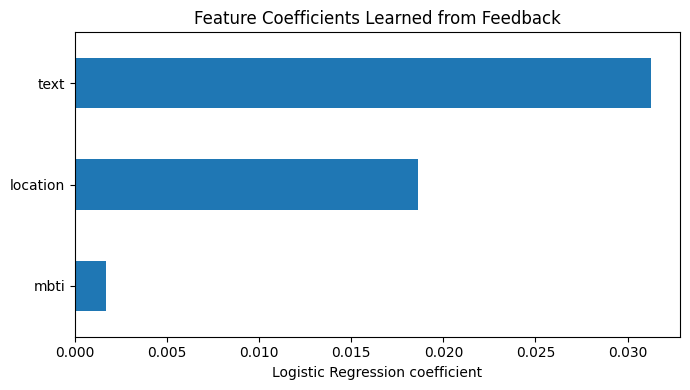

In [ ]:
coefficients = pd.Series(
    feedback_model.coef_[0],
    index=X.columns
)

display(coefficients.to_frame("Learned coefficient"))

coefficients.sort_values().plot(
    kind="barh",
    figsize=(7, 4)
)

plt.title("Feature Coefficients Learned from Feedback")
plt.xlabel("Logistic Regression coefficient")
plt.tight_layout()
plt.show()

In [ ]:
def recommend_matches(user_id, top_n=5, use_feedback=False):
    if user_id not in user_index:
        raise ValueError(f"Unknown user ID: {user_id}")

    target = users_df.iloc[user_index[user_id]]
    results = []

    for _, candidate in users_df.iterrows():
        candidate_id = candidate["user_id"]

        if candidate_id == user_id:
            continue

        features = calculate_pair_features(
            user_id, candidate_id
        )

        baseline_score = calculate_compatibility(
            user_id, candidate_id
        )

        feature_frame = pd.DataFrame(
            [[features["text"], features["mbti"],
              features["location"]]],
            columns=["text", "mbti", "location"]
        )

        predicted_acceptance = (
            feedback_model.predict_proba(feature_frame)[0, 1]
            * 100
        )

        results.append({
            "user_id": candidate_id,
            "name": candidate["name"],
            "profession": candidate["profession"],
            "location": candidate["location"],
            "text_similarity": round(features["text"], 2),
            "mbti_score": round(features["mbti"], 2),
            "location_score": round(features["location"], 2),
            "compatibility_score": baseline_score,
            "predicted_acceptance": round(
                predicted_acceptance, 2
            )
        })

    results_df = pd.DataFrame(results)

    ranking_column = (
        "predicted_acceptance"
        if use_feedback else "compatibility_score"
    )

    return results_df.sort_values(
        ranking_column,
        ascending=False
    ).head(top_n).reset_index(drop=True)

In [ ]:
test_user_id = users_df.iloc[0]["user_id"]

print("Selected user:")
display(users_df[users_df["user_id"] == test_user_id][
    ["user_id", "name", "profession", "location"]
])

print("BASELINE TOP 5 MATCHES")
display(recommend_matches(test_user_id, top_n=5))

print("FEEDBACK-BASED TOP 5 MATCHES")
display(recommend_matches(
    test_user_id, top_n=5, use_feedback=True
))

Selected user:


,user_id,name,profession,location
0,U001,User001,Data Analyst,Mumbai


BASELINE TOP 5 MATCHES


,user_id,name,profession,location,text_similarity,mbti_score,location_score,compatibility_score,predicted_acceptance
0,U041,User041,Data Analyst,Mumbai,33.35,100.0,100.0,66.68,74.13
1,U021,User021,Data Analyst,Kochi,40.55,100.0,40.0,58.27,54.04
2,U081,User081,Data Analyst,Hyderabad,54.39,75.0,40.0,57.70,63.49
3,U093,User093,Machine Learning Engineer,Mumbai,10.79,75.0,100.0,47.90,57.58
4,U061,User061,Data Analyst,Pune,33.06,75.0,40.0,47.03,47.16


FEEDBACK-BASED TOP 5 MATCHES


,user_id,name,profession,location,text_similarity,mbti_score,location_score,compatibility_score,predicted_acceptance
0,U041,User041,Data Analyst,Mumbai,33.35,100.0,100.0,66.68,74.13
1,U055,User055,Business Analyst,Mumbai,22.63,25.0,100.0,38.82,64.40
2,U081,User081,Data Analyst,Hyderabad,54.39,75.0,40.0,57.70,63.49
3,U075,User075,Business Analyst,Mumbai,14.44,50.0,100.0,42.22,59.34
4,U058,User058,Environmental Scientist,Mumbai,13.96,50.0,100.0,41.98,58.98


In [ ]:
import gradio as gr

def show_matches(user_name, ranking_method):
    selected = users_df[users_df["name"] == user_name]

    if selected.empty:
        return pd.DataFrame()

    selected_id = selected.iloc[0]["user_id"]

    use_feedback = ranking_method == "Feedback-based ML"

    result = recommend_matches(
        selected_id,
        top_n=5,
        use_feedback=use_feedback
    )

    return result[
        [
            "user_id", "name", "profession", "location",
            "compatibility_score", "predicted_acceptance"
        ]
    ]

with gr.Blocks(title="Profile-Based Matching Algorithm") as demo:
    gr.Markdown("# Intelligent Hybrid Recommendation System")
    gr.Markdown(
        "Find compatible profiles using NLP, MBTI heuristics, "
        "location and simulated feedback."
    )

    user_dropdown = gr.Dropdown(
        choices=users_df["name"].tolist(),
        value=users_df["name"].iloc[0],
        label="Select user profile"
    )

    ranking_method = gr.Radio(
        choices=["Baseline hybrid score", "Feedback-based ML"],
        value="Baseline hybrid score",
        label="Recommendation method"
    )

    find_button = gr.Button("Find Top 5 Matches")

    output_table = gr.Dataframe(
        label="Recommended profiles",
        interactive=False
    )

    find_button.click(
        fn=show_matches,
        inputs=[user_dropdown, ranking_method],
        outputs=output_table
    )

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2366871ec5f56a74e9.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# Export final recommendation examples.
recommend_matches(
    users_df.iloc[0]["user_id"],
    top_n=5
).to_csv("baseline_top5.csv", index=False)

recommend_matches(
    users_df.iloc[0]["user_id"],
    top_n=5,
    use_feedback=True
).to_csv("feedback_top5.csv", index=False)

# Export model evaluation metrics.
metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_test, predictions),
    "precision": precision_score(
        y_test, predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, predictions, zero_division=0
    ),
    "f1_score": f1_score(
        y_test, predictions, zero_division=0
    )
}])

metrics.to_csv("model_evaluation.csv", index=False)

print("Output files saved successfully!")
display(metrics)

Output files saved successfully!


,accuracy,precision,recall,f1_score
0,0.66875,0.48,0.230769,0.311688
